# Introducción a los LLMs y Configuración del Entorno

## ¿Qué son los LLMs? Primeros Pasos con LangChain y Groq

Los **Modelos de Lenguaje Grande (LLMs)** son sistemas de inteligencia artificial diseñados para comprender, generar e interactuar con el lenguaje humano de manera profunda. Han aprendido la estructura del lenguaje procesando cantidades masivas de texto (corpus).

Para comenzar, estableceremos la conexión con un modelo avanzado: **Llama 3.3 (70 mil millones de parámetros)**. Usaremos la infraestructura de **Groq** (conocida por su altísima velocidad de inferencia) a través de **LangChain**, un marco de trabajo (*framework*) que facilita la construcción de aplicaciones impulsadas por IA.

En esta fase de configuración:

1. Aseguramos nuestras credenciales de acceso.
2. Instanciamos el modelo definiendo su parámetro de **temperatura** (que controla la creatividad vs. precisión matemática de la respuesta).
3. Realizamos nuestra primera invocación (consulta) al modelo.

In [ ]:
!pip install -qU langchain-groq langgraph

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 247.8/247.8 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 6.8 MB/s eta 0:00:00


In [ ]:
import os
from google.colab import userdata
from langchain_groq import ChatGroq

os.environ["GROQ_API_KEY"] = userdata.get('GROQ_API_KEY')

llm = ChatGroq(
    model="llama-3.3-70b-versatile",
    temperature=1
)

respuesta = llm.invoke("Hola")

print(respuesta.content)

Hola, ¿en qué puedo ayudarte?


# Unidades Básicas de Texto: Tokens y Predicción Probabilística

## ¿Cómo "Lee" y "Escribe" un LLM? Tokens y Probabilidades

A diferencia de los humanos, que leemos palabras o frases enteras basándonos en su significado visual y fonético, los Modelos de Lenguaje Grande procesan la información de manera estrictamente numérica. Para lograr esto, utilizan un proceso llamado **Tokenización**.

- **Tokens:** Son las unidades atómicas de texto. Un modelo no procesa palabras enteras, sino que divide el texto en fragmentos que pueden ser palabras, sílabas, subpalabras o incluso caracteres individuales. Por ejemplo, la palabra "gato" podría ser un solo token, pero una palabra poco común como "inconstitucionalidad" podría dividirse en múltiples tokens ("in", "constitu", "cional", "idad"). Cada token se mapea a un número entero (un ID único en el vocabulario del modelo).
- **Predicción de Tokens (Autoregresión):** El funcionamiento central de un LLM como Llama-3 consiste en un juego matemático de probabilidades. Dado un contexto (una secuencia de tokens de entrada), el modelo calcula una distribución de probabilidad sobre todo su vocabulario para adivinar cuál es el **siguiente token más lógico**. Una vez que genera ese token, lo añade al contexto y repite el proceso para predecir el siguiente, construyendo oraciones paso a paso.

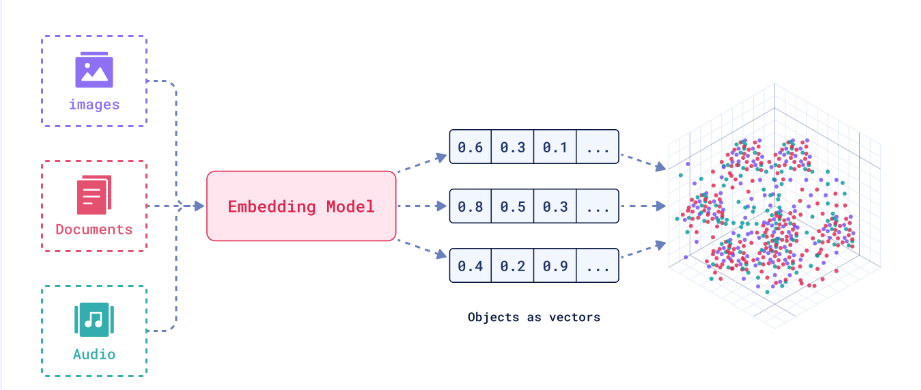

In [ ]:
# 1. Diseñamos un prompt predecible para forzar la predicción estadística.
# Cambiamos el refrán clásico por otro muy popular. Estadísticamente,
# el modelo le asignará casi un 100% de probabilidad a la palabra que falta.
prompt_incompleto = "Completa este refrán popular: Camarón que se duerme, se lo lleva la..."

print(f"Prompt enviado: '{prompt_incompleto}'\n")

# 2. Invocamos al modelo
respuesta_prediccion = llm.invoke(prompt_incompleto)

# 3. Observamos la predicción generada
print("=== Predicción del Modelo ===")
# El modelo probabilísticamente sabe que después de "la..." sigue "corriente"
print(respuesta_prediccion.content)
print("\n")

# 4. Análisis de Tokens consumidos y generados
# LangChain almacena los metadatos de la API, incluyendo la contabilidad de los tokens.
metadatos = respuesta_prediccion.response_metadata

# Extraemos el diccionario que contiene el uso de tokens (token_usage)
uso_de_tokens = metadatos.get('token_usage', {})

print("=== Análisis de Tokens (Métricas Internas) ===")
# prompt_tokens: ¿Cuántos fragmentos numéricos leyó el modelo?
tokens_entrada = uso_de_tokens.get('prompt_tokens', 0)
print(f"Tokens leídos (Input): {tokens_entrada}")

# completion_tokens: ¿Cuántos fragmentos numéricos generó el modelo para responder?
tokens_salida = uso_de_tokens.get('completion_tokens', 0)
print(f"Tokens generados (Output): {tokens_salida}")

# total_tokens: El costo computacional total de esta transacción.
tokens_totales = uso_de_tokens.get('total_tokens', 0)
print(f"Costo total en tokens: {tokens_totales}")

Prompt enviado: 'Completa este refrán popular: Camarón que se duerme, se lo lleva la...'

=== Predicción del Modelo ===
La corriente.


=== Análisis de Tokens (Métricas Internas) ===
Tokens leídos (Input): 57
Tokens generados (Output): 6
Costo total en tokens: 63


# Representación Matemática del Lenguaje: Embeddings

## El Espacio Semántico y la Similitud Vectorial

Para que un modelo de inteligencia artificial entienda el "significado" de las palabras, primero debe traducirlas al único lenguaje que comprende: **los números y el álgebra lineal**. Aquí es donde entran los **Embeddings**.

- **Representaciones Vectoriales:** Un embedding transforma una palabra (o un token) en un vector denso (una matriz o lista de números, como coordenadas en un mapa espacial multidimensional). En lugar de asignar un identificador aleatorio, cada número en el vector codifica una característica abstracta de la palabra. Mientras nosotros usamos 3 dimensiones para el espacio físico, los LLMs usan miles de dimensiones para mapear conceptos.
- **Similitud Semántica:** La magia de los embeddings es que mapean el significado espacialmente. Palabras con contextos similares se sitúan cerca unas de otras en este espacio matemático. Por ejemplo, los vectores de "Perro" y "Gato" estarán muy próximos, mientras que el de "Automóvil" estará lejos.

Para medir qué tan cerca están dos conceptos, la inteligencia artificial utiliza la **Similitud del Coseno**, calculando el ángulo entre ambos vectores. La fórmula matemática es:

$Similitud = \frac{A \cdot B}{\vert{}\vert{}A\vert{}\vert{} \times \vert{}\vert{}B\vert{}\vert{}}$

Esta geometría del lenguaje permite a los LLMs hacer literalmente matemáticas con conceptos.

In [ ]:
import numpy as np
from numpy.linalg import norm


# En un LLM real (como Llama 3), estas dimensiones superan las 4000 y son abstractas,
# pero para entenderlo, imaginemos que nuestras 3 dimensiones representan:
# [Nivel de Animalidad, Nivel de Domesticación, Nivel de Tamaño]

# Un perro es muy animal (0.9), muy doméstico (0.9) y de tamaño medio (0.5)
embedding_perro = np.array([0.9, 0.9, 0.5])

# Un gato es muy animal (0.9), doméstico (0.8) y de tamaño pequeño (0.2)
embedding_gato = np.array([0.9, 0.8, 0.2])

# Un automóvil no es animal (0.0), no es biológicamente doméstico (0.1) y es grande (0.9)
embedding_coche = np.array([0.0, 0.1, 0.9])

# 2. Definimos la función matemática clave en IA: Similitud del Coseno.
# Mide el coseno del ángulo entre dos vectores en el espacio.
# Un resultado cercano a 1.0 significa alta similitud (apuntan al mismo lado).
# Un resultado cercano a 0.0 significa baja o nula similitud.
def similitud_coseno(vector_a, vector_b):
    # Producto escalar (dot product) dividido por la multiplicación de sus magnitudes (normas)
    return np.dot(vector_a, vector_b) / (norm(vector_a) * norm(vector_b))

# 3. Ejecutamos el cálculo de similitudes semánticas
sim_perro_gato = similitud_coseno(embedding_perro, embedding_gato)
sim_perro_coche = similitud_coseno(embedding_perro, embedding_coche)

# 4. Mostramos los resultados de la operación
print("=== Análisis de Similitud Semántica (Embeddings) ===\n")
print(f"Similitud matemática entre 'Perro' y 'Gato': {sim_perro_gato:.4f} (Alta)")
print(f"Similitud matemática entre 'Perro' y 'Coche': {sim_perro_coche:.4f} (Baja)\n")

# 5. Lógica condicional de cómo agruparía esto un modelo de Machine Learning:
if sim_perro_gato > sim_perro_coche:
    print("Conclusión del Modelo: 'Perro' y 'Gato' comparten un espacio semántico.")
    print("Si el usuario busca productos para mascotas, podemos recomendarle ambos.")

=== Análisis de Similitud Semántica (Embeddings) ===

Similitud matemática entre 'Perro' y 'Gato': 0.9765 (Alta)
Similitud matemática entre 'Perro' y 'Coche': 0.4361 (Baja)

Conclusión del Modelo: 'Perro' y 'Gato' comparten un espacio semántico.
Si el usuario busca productos para mascotas, podemos recomendarle ambos.


# Arquitectura y Contexto: Transformers y Mecanismo de Atención

## El Motor de los LLMs: Paralelismo y Foco Matemático

La arquitectura **Transformer**, introducida en 2017, revolucionó la Inteligencia Artificial al resolver el mayor problema de los modelos antiguos: la pérdida de memoria a largo plazo al leer textos largos. Su componente estrella es el **Mecanismo de Atención**.

- **Transformers:** A diferencia de los modelos anteriores que leían palabra por palabra (secuencialmente), los transformers procesan secuencias enteras de datos en paralelo. Esto no solo acelera el entrenamiento usando tarjetas gráficas (GPUs), sino que permite analizar la frase completa de una sola vez.
- **Mecanismo de Atención (Self-Attention):** Es la fórmula matemática que permite al modelo decidir qué tokens son cruciales para entender el contexto actual. Si el modelo lee *"El* ***banco*** *del parque estaba roto, así que no me pude sentar"*, el mecanismo de atención fuerza a la palabra "banco" a conectarse fuertemente con "parque" y "sentar", ignorando significados financieros.

A continuación, construiremos una simulación matemática simplificada de cómo las palabras "se prestan atención" entre sí usando matrices.

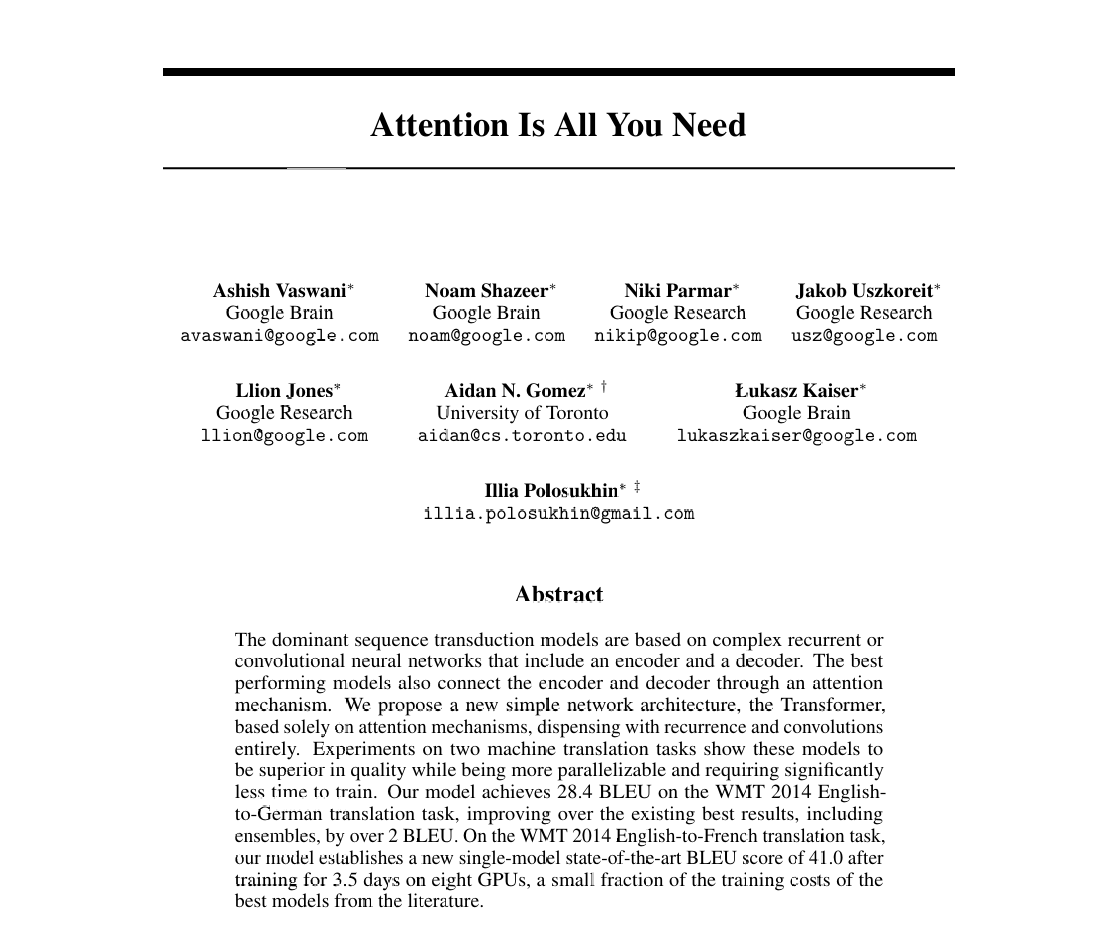

In [ ]:
import numpy as np

# En la arquitectura Transformer, cada token (palabra) se transforma en 3 vectores distintos:
# 1. Query (Q) -> Lo que la palabra está "buscando" en la oración.
# 2. Key (K)   -> Lo que la palabra "ofrece" a las demás.
# 3. Value (V) -> El contenido real de la palabra (omitido aquí por simplicidad).

# 1. Definimos una frase de ejemplo de 3 tokens:
palabras = ["El", "banco", "roto"]

# 2. Simulamos los vectores Query (Q) y Key (K) generados por la red neuronal para cada palabra.
# Imaginemos un espacio vectorial muy pequeño, de solo 3 dimensiones.
# Estos números son los "embeddings" que el modelo aprendió durante su entrenamiento.

# Matrices de 3 palabras x 3 dimensiones
Q = np.array([
    [0.1, 0.0, 0.1],  # Query de "El"
    [0.8, 0.2, 0.9],  # Query de "banco" (busca adjetivos sobre su estado o ubicación)
    [0.1, 0.9, 0.1]   # Query de "roto"
])

K = np.array([
    [0.1, 0.1, 0.0],  # Key de "El"
    [0.7, 0.1, 0.8],  # Key de "banco"
    [0.9, 0.3, 0.8]   # Key de "roto" (ofrece información sobre el estado de un objeto)
])

print("=== Calculando los Puntajes de Atención (Raw Scores) ===\n")

# 3. Multiplicación de Matrices (Q x K transpuesta):
# Matemáticamente, el nivel de atención que la palabra A presta a la palabra B
# se calcula multiplicando su Query con el Key de la otra (producto punto).
# Si los vectores apuntan en la misma dirección, el resultado será un número alto.

puntajes_crudos = np.dot(Q, K.T)

# 4. Función Softmax:
# Las redes neuronales usan Softmax para convertir esos puntajes crudos
# en porcentajes (probabilidades) que sumen 1 (o 100%).
def aplicar_softmax(x):
    # La exponencial resalta los valores altos y aplasta los bajos
    e_x = np.exp(x - np.max(x, axis=-1, keepdims=True))
    return e_x / np.sum(e_x, axis=-1, keepdims=True)

matriz_atencion = aplicar_softmax(puntajes_crudos)

# 5. Visualización del Mecanismo de Atención:
print("¿A qué palabras presta atención la palabra 'banco'?\n")

# Extraemos la segunda fila (índice 1) que corresponde a "banco"
atencion_de_banco = matriz_atencion[1]

for i, palabra in enumerate(palabras):
    porcentaje = atencion_de_banco[i] * 100
    print(f"Atención sobre '{palabra}': {porcentaje:.2f}%")

# Conclusión para la IA: El mecanismo calcula matemáticamente que
# la Query de "banco" y el Key de "roto" hacen "match".
# Así el LLM sabe que el banco es un objeto físico dañado, no una institución financiera.

=== Calculando los Puntajes de Atención (Raw Scores) ===

¿A qué palabras presta atención la palabra 'banco'?

Atención sobre 'El': 11.94%
Atención sobre 'banco': 39.64%
Atención sobre 'roto': 48.42%


# Capacidades Avanzadas: Comprensión, Análisis y Resumen

## Extrayendo Valor: De los Datos Desestructurados a la Inteligencia Accionable

Una vez que un LLM ha dominado la representación matemática del lenguaje (mediante *Embeddings*) y el contexto direccional (mediante el mecanismo de *Atención* en la arquitectura *Transformer*), emergen lo que llamamos **capacidades cognitivas avanzadas**.

El modelo ya no solo predice la siguiente palabra al azar, sino que demuestra una **comprensión profunda de lenguaje natural**. Esto le permite realizar tareas analíticas complejas sobre textos extensos (datos desestructurados), tales como:

- **Análisis de Sentimientos:** Inferir el tono emocional, la intención subyacente y la polaridad (positiva, negativa, neutral) de un texto, detectando incluso ironía o frustración.
- **Resumen de Textos Extensos:** Destilar la información clave de páginas enteras de texto, omitiendo redundancias y manteniendo el núcleo semántico intacto.
- **Razonamiento Lógico:** Seguir instrucciones paso a paso, clasificar información basándose en reglas dadas y extraer entidades específicas (nombres, fechas, montos) de un mar de palabras.

A continuación, pondremos a prueba nuestro modelo `Llama-3.3-70b-versatile` aplicando técnicas de *Prompt Engineering* (Ingeniería de Instrucciones) para forzarlo a analizar un texto complejo desde múltiples ángulos.

In [ ]:
import os
# Importamos utilidades de LangChain para crear plantillas de instrucciones estructuradas
from langchain_core.prompts import PromptTemplate
from langchain_groq import ChatGroq
from google.colab import userdata

# 1. Configuración del modelo (Reutilizando las credenciales previas)
os.environ["GROQ_API_KEY"] = userdata.get('GROQ_API_KEY')

# Mantenemos una temperatura muy baja (0.1) porque queremos análisis precisos
# y extracción factual, no queremos que el modelo invente datos (alucine).
llm_analista = ChatGroq(
    model="llama-3.3-70b-versatile",
    temperature=0.1
)

texto_cliente = """
El servicio de atención al cliente de TechGlobal fue una pesadilla ayer 14 de marzo.
Compré el ordenador portátil X-Pro 5000 por 1200 dólares esperando recibirlo en 2 días
como prometía la web. Llegó dos semanas tarde, con la caja abollada y sin el cargador.
Cuando llamé, la operadora (creo que se llamaba Marta) fue muy amable, pero el sistema
se cayó tres veces y no pudo tramitar mi reembolso. Es inaceptable que una empresa
tecnológica tenga un sistema interno tan defectuoso, aunque valoro la paciencia de su personal.
"""


plantilla_analisis = """
Eres un analista de datos de Inteligencia Artificial altamente capacitado.
Tu tarea es leer el siguiente texto de un cliente y extraer exactamente la información solicitada.

TEXTO DEL CLIENTE:
{texto}

TAREAS:
1. Resumen: Resume el problema en una sola oración concisa.
2. Sentimiento: Clasifica el sentimiento general (Positivo, Negativo o Neutral) y justifícalo en 10 palabras.
3. Extracción de Entidades: Enumera el producto, el precio y la fecha mencionada.
4. Razonamiento: ¿Quién es el culpable del fallo final, el empleado o la infraestructura de la empresa?

Responde utilizando únicamente la estructura numerada anterior.
"""

prompt_formateado = PromptTemplate.from_template(plantilla_analisis).format(texto=texto_cliente)

print("Enviando texto desestructurado al LLM para su análisis profundo...\n")

# Invocamos al modelo con las instrucciones complejas
respuesta_analitica = llm_analista.invoke(prompt_formateado)

# 5. Visualización de los Resultados
print("=== Resultados del Análisis de Inteligencia Artificial ===")
print(respuesta_analitica.content)

Enviando texto desestructurado al LLM para su análisis profundo...

=== Resultados del Análisis de Inteligencia Artificial ===
1. Resumen: El cliente experimentó problemas con la entrega y el servicio de atención al cliente de TechGlobal.
2. Sentimiento: Negativo, debido a la mala experiencia y fallos técnicos.
3. Extracción de Entidades: 
   - Producto: Ordenador portátil X-Pro 5000
   - Precio: 1200 dólares
   - Fecha: 14 de marzo
4. Razonamiento: La infraestructura de la empresa es el culpable del fallo final, ya que el sistema se cayó tres veces, impidiendo que el empleado tramitara el reembolso.


# Ciclo de Vida: Entrenamiento Inicial y Ajuste Fino (Fine-Tuning)

## De la Comprensión General a la Especialización Experta

El desarrollo de un Modelo de Lenguaje Grande como Llama-3 o GPT-4 no ocurre en un solo paso. Es un proceso de dos fases principales que asemeja la educación humana: primero la escuela general, luego la especialización universitaria.

- **Entrenamiento Inicial (Pre-training):** Es la fase más costosa y masiva. El modelo se expone a un corpus gigantesco (terabytes de datos de Internet, Wikipedia, libros, artículos científicos). Su único objetivo aquí es aprender la estructura del lenguaje mediante la *predicción de tokens*. Durante meses, ajusta sus billones de parámetros para aprender gramática, hechos del mundo, razonamiento lógico y múltiples idiomas. El resultado es un modelo "fundacional" que sabe mucho, pero no sabe cómo comportarse como un asistente útil.
- **Fine-Tuning (Ajuste Fino):** Tomamos ese modelo pre-entrenado y lo entrenamos un poco más, pero esta vez con un conjunto de datos mucho más pequeño, curado y altamente específico. Esto altera ligeramente sus parámetros internos (pesos) para especializarlo. Por ejemplo, si lo entrenamos con miles de diagnósticos, se convierte en un modelo médico; si le damos sentencias judiciales, se vuelve un asistente legal.

A continuación, en lugar de invocar una API, escribiremos el código para **preparar los datos exactos** que se necesitan para realizar un Fine-Tuning. Aprenderemos el formato estándar de la industria para enseñar a un modelo a ser un experto legal.

In [ ]:
import json

instruccion_sistema = "Eres un asistente legal experto en derecho corporativo. Responde siempre con jerga legal precisa y cita el tipo de contrato."

datos_entrenamiento_legal = [
    {
        "messages": [
            {"role": "system", "content": instruccion_sistema},
            {"role": "user", "content": "Dos empresas quieren colaborar pero sin fusionarse. ¿Qué documento necesitan?"},
            # El "Assistant" contiene la respuesta perfecta que queremos que el modelo APRENDA a replicar.
            {"role": "assistant", "content": "Se requiere un Contrato de Joint Venture o un Acuerdo de Asociación Estratégica (Memorándum de Entendimiento - MoU), dependiendo del nivel de integración financiera deseada."}
        ]
    },
    {
        "messages": [
            {"role": "system", "content": instruccion_sistema},
            {"role": "user", "content": "Voy a compartir una idea de negocio con un inversor, no quiero que me la robe."},
            {"role": "assistant", "content": "Es imperativo redactar y firmar un Acuerdo de Confidencialidad (NDA - Non-Disclosure Agreement) antes de revelar cualquier secreto comercial o propiedad intelectual."}
        ]
    }
]

nombre_archivo = "dataset_legal_finetuning.jsonl"

print(f"Generando archivo de entrenamiento: {nombre_archivo}...\n")

with open(nombre_archivo, 'w', encoding='utf-8') as archivo:
    for ejemplo in datos_entrenamiento_legal:
        # Convertimos el diccionario de Python a un string JSON y lo guardamos
        linea_json = json.dumps(ejemplo, ensure_ascii=False)
        archivo.write(linea_json + '\n')

print("=== Archivo JSONL creado exitosamente ===")
print("Muestra de la primera línea del archivo listo para inyectarse en el algoritmo de entrenamiento:")
print("-" * 50)


with open(nombre_archivo, 'r', encoding='utf-8') as archivo:
    primera_linea = archivo.readline()
    print(primera_linea)

Generando archivo de entrenamiento: dataset_legal_finetuning.jsonl...

=== Archivo JSONL creado exitosamente ===
Muestra de la primera línea del archivo listo para inyectarse en el algoritmo de entrenamiento:
--------------------------------------------------
{"messages": [{"role": "system", "content": "Eres un asistente legal experto en derecho corporativo. Responde siempre con jerga legal precisa y cita el tipo de contrato."}, {"role": "user", "content": "Dos empresas quieren colaborar pero sin fusionarse. ¿Qué documento necesitan?"}, {"role": "assistant", "content": "Se requiere un Contrato de Joint Venture o un Acuerdo de Asociación Estratégica (Memorándum de Entendimiento - MoU), dependiendo del nivel de integración financiera deseada."}]}

